# Flight disruption prediction (CDS 4003)
Salem Marwan Alebri (H00472169) and Ebrahim Abdulaziz Mohamed Ibrahim Almarzouqi (H00442189)

## 1. Business problem
Delays and cancellations create extra work for airline support staff. We want to predict from the planned schedule if a flight will be **disrupted** (cancelled, diverted, or arriving 15+ minutes late), so staff know which flights may need attention.
Goal: compare two models and pick the one with the better F1 score.

## 2. Dataset
- Source: [US DOT 2015 Flight Delays and Cancellations (Kaggle)](https://www.kaggle.com/datasets/usdot/flight-delays), licence CC0 Public Domain.
- The full file has 5,819,079 rows. We use a random sample of **250,000 rows and all 31 columns** (`data/flights.csv.gz`).
- The full file is too big for GitHub (590 MB), so we saved a sample. The commented code below shows how we made it.
- Other datasets we looked at are listed in the README.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# load the data
data = pd.read_csv('data/flights.csv.gz', dtype={'ORIGIN_AIRPORT': str, 'DESTINATION_AIRPORT': str})
print(data.shape)
data.head()

(250000, 31)


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,4,7,2,EV,4900,N759EV,FWA,DTW,1340,...,1423.0,-13.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,24,6,AS,611,N413AS,LAS,SEA,1910,...,2133.0,-12.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,7,8,3,WN,1483,N463WN,OAK,SEA,630,...,812.0,-8.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,5,26,2,WN,193,N7745A,STL,DAL,810,...,1222.0,152.0,0,0,NaN,0.0,0.0,0.0,152.0,0.0
4,2015,7,6,1,UA,253,N213UA,IAH,HNL,1000,...,1316.0,-2.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
# How the sample was made (only run this if you downloaded flights.csv from Kaggle):
# full = pd.read_csv('flights.csv', dtype={'ORIGIN_AIRPORT': str, 'DESTINATION_AIRPORT': str})
# full.sample(n=250000, random_state=42).to_csv('data/flights.csv.gz', index=False)

## 3. Data cleaning
First we check missing values, duplicates and basic statistics.

Cleaning decisions:
- Remove exact duplicates.
- Remove rows where the outcome is unknown (no arrival delay and not cancelled/diverted).
- Impossible values (distance or duration 0 or below, wrong clock times) become missing, then get filled with the median.
- Negative arrival delays are early arrivals, so we keep them. Long flights are real, so we keep them too.
- In October airport codes are numbers, not letters (inconsistent format). We do not use airports as inputs, so we leave them as they are.
- Columns recorded after the flight (actual times, delay causes) are **not** used as inputs.

In [3]:
# check duplicates and missing values
print('Duplicates:', data.duplicated().sum())
print(data.isnull().sum())

Duplicates: 0
YEAR                        0
MONTH                       0
DAY                         0
DAY_OF_WEEK                 0
AIRLINE                     0
FLIGHT_NUMBER               0
TAIL_NUMBER               633
ORIGIN_AIRPORT              0
DESTINATION_AIRPORT         0
SCHEDULED_DEPARTURE         0
DEPARTURE_TIME           3646
DEPARTURE_DELAY          3646
TAXI_OUT                 3769
WHEELS_OFF               3769
SCHEDULED_TIME              0
ELAPSED_TIME             4420
AIR_TIME                 4420
DISTANCE                    0
WHEELS_ON                3917
TAXI_IN                  3917
SCHEDULED_ARRIVAL           0
ARRIVAL_TIME             3917
ARRIVAL_DELAY            4420
DIVERTED                    0
CANCELLED                   0
CANCELLATION_REASON    246194
AIR_SYSTEM_DELAY       204276
SECURITY_DELAY         204276
AIRLINE_DELAY          204276
LATE_AIRCRAFT_DELAY    204276
WEATHER_DELAY          204276
dtype: int64


In [4]:
# basic statistics to look for outliers
print(data[['DISTANCE', 'SCHEDULED_TIME', 'ARRIVAL_DELAY']].describe())

# in October the airport codes are numbers instead of letters
print('Number airport codes:', data['ORIGIN_AIRPORT'].str.isdigit().sum())

            DISTANCE  SCHEDULED_TIME  ARRIVAL_DELAY
count  250000.000000   250000.000000  245580.000000
mean      821.806192      141.615456       4.466113
std       607.088070       75.175584      39.588306
min        31.000000       18.000000     -81.000000
25%       373.000000       85.000000     -13.000000
50%       646.000000      122.000000      -5.000000
75%      1062.000000      173.000000       8.000000
max      4983.000000      718.000000    1557.000000
Number airport codes: 20879


## 4. EDA and new features
New features: `DEPARTURE_HOUR` (from the planned departure time) and `IS_WEEKEND` (Saturday or Sunday).

In [5]:
# remove duplicates
data = data.drop_duplicates()

# remove rows where we do not know the outcome
data = data[(data['CANCELLED'] == 1) | (data['DIVERTED'] == 1) | (data['ARRIVAL_DELAY'].notnull())]

# make the target: 1 = disrupted, 0 = normal
data['DISRUPTED'] = 0
data.loc[data['CANCELLED'] == 1, 'DISRUPTED'] = 1
data.loc[data['DIVERTED'] == 1, 'DISRUPTED'] = 1
data.loc[data['ARRIVAL_DELAY'] >= 15, 'DISRUPTED'] = 1

# distance and time cannot be 0 or negative
data = data[data['DISTANCE'] > 0]
data = data[data['SCHEDULED_TIME'] > 0]

print('Rows after cleaning:', len(data))
print('Disrupted flights %:', round(data['DISRUPTED'].mean() * 100, 2))

Rows after cleaning: 250000
Disrupted flights %: 20.06


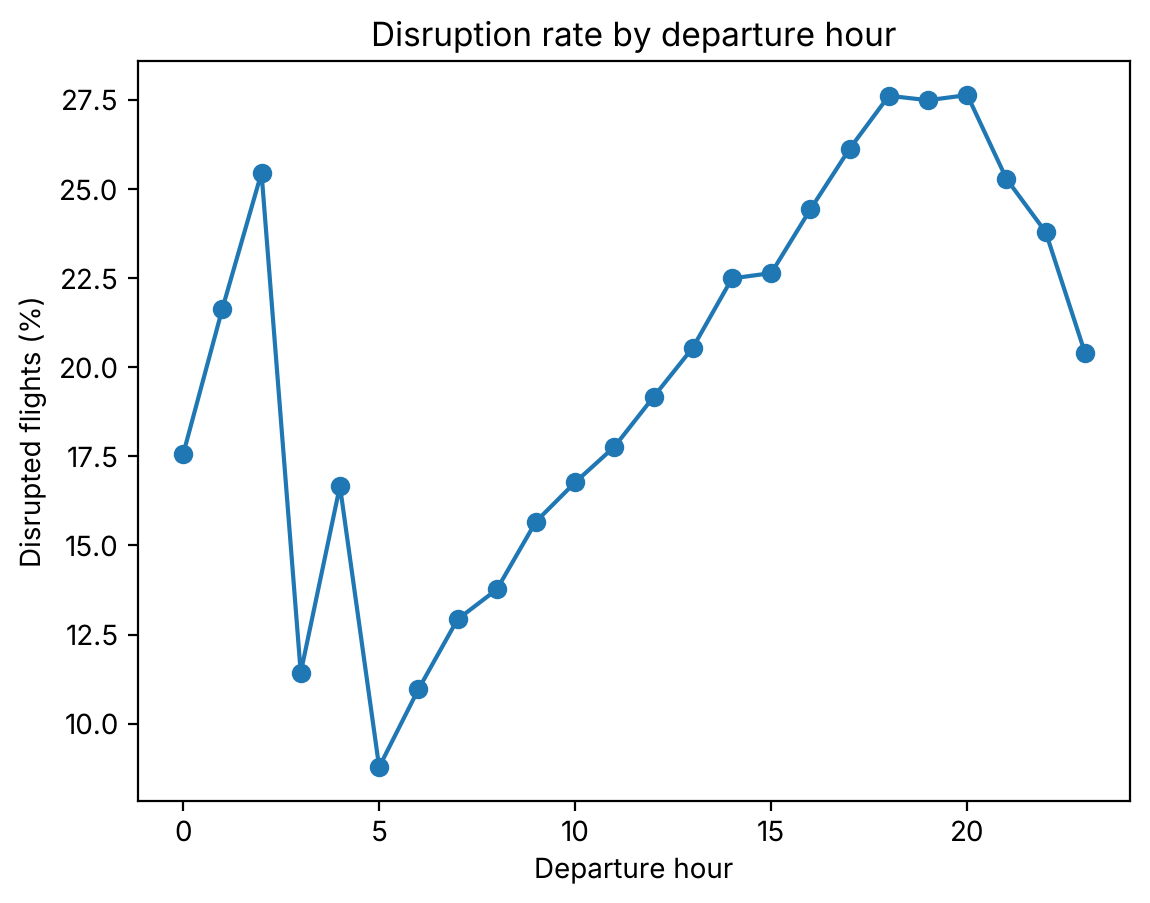

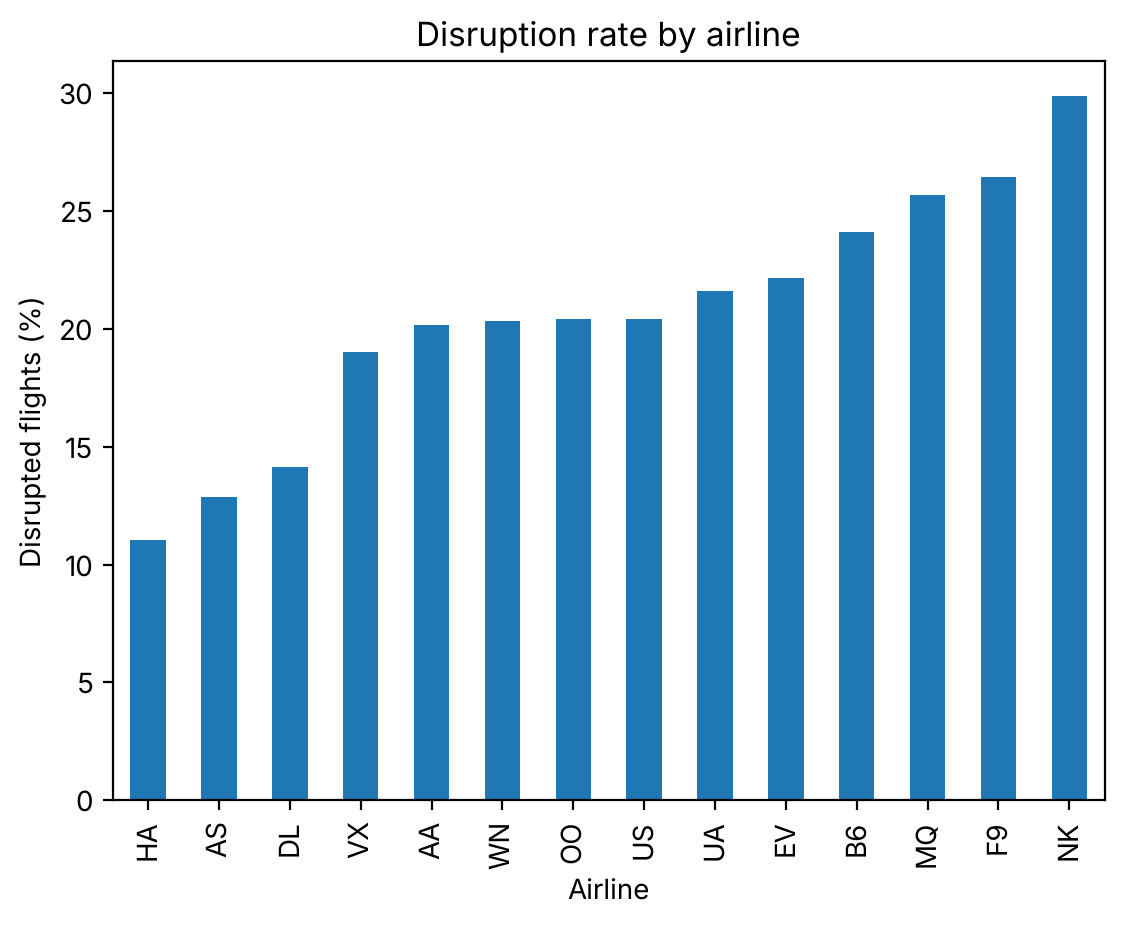

In [6]:
# new features
data['DEPARTURE_HOUR'] = data['SCHEDULED_DEPARTURE'] // 100
data.loc[data['DEPARTURE_HOUR'] == 24, 'DEPARTURE_HOUR'] = 0
data['IS_WEEKEND'] = 0
data.loc[data['DAY_OF_WEEK'] >= 6, 'IS_WEEKEND'] = 1

# chart 1: disruption by departure hour
hour_rate = data.groupby('DEPARTURE_HOUR')['DISRUPTED'].mean() * 100
hour_rate.plot(marker='o')
plt.title('Disruption rate by departure hour')
plt.xlabel('Departure hour')
plt.ylabel('Disrupted flights (%)')
plt.show()

# chart 2: disruption by airline
airline_rate = data.groupby('AIRLINE')['DISRUPTED'].mean().sort_values() * 100
airline_rate.plot(kind='bar')
plt.title('Disruption rate by airline')
plt.xlabel('Airline')
plt.ylabel('Disrupted flights (%)')
plt.show()

**Findings:** the disruption rate is different between airlines (about 11% to 30%) and it is higher for evening flights. Early morning flights are disrupted less. Very early hours have few flights, so those points are less reliable.

## 5. Two models
- **Logistic regression:** a simple model that gives each input a weight.
- **Decision tree:** asks a series of yes/no questions (for example, "is departure after 17:00?").

The airline is changed to 0/1 columns with `get_dummies`. We split the data 80% train and 20% test. Both models use `class_weight='balanced'` because only about 20% of flights are disrupted.

In [7]:
# inputs (X) and target (y)
X = data[['MONTH', 'DAY_OF_WEEK', 'DEPARTURE_HOUR', 'IS_WEEKEND', 'DISTANCE', 'SCHEDULED_TIME', 'AIRLINE']]
X = pd.get_dummies(X, columns=['AIRLINE'])
y = data['DISRUPTED']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', len(X_train), 'Test:', len(X_test))

Train: 200000 Test: 50000


## 6. Tuning and evaluation
We use GridSearchCV with 3 folds and the F1 score.
- Logistic regression: try C = 0.1, 1, 10
- Decision tree: try max_depth = 3, 5, 8

Metrics: precision = how many alerts are correct, recall = how many real disruptions we find, F1 = balance of both. Accuracy alone is misleading because most flights are normal.

In [8]:
# logistic regression needs scaled numbers
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# tune logistic regression
log_model = GridSearchCV(LogisticRegression(class_weight='balanced', max_iter=1000), {'C': [0.1, 1, 10]}, scoring='f1', cv=3)
log_model.fit(X_train_scaled, y_train)
print('Logistic regression best C:', log_model.best_params_, 'F1:', round(log_model.best_score_, 3))

# tune decision tree
tree_model = GridSearchCV(DecisionTreeClassifier(class_weight='balanced', random_state=42), {'max_depth': [3, 5, 8]}, scoring='f1', cv=3)
tree_model.fit(X_train, y_train)
print('Decision tree best depth:', tree_model.best_params_, 'F1:', round(tree_model.best_score_, 3))

Logistic regression best C: {'C': 0.1} F1: 0.368


Decision tree best depth: {'max_depth': 8} F1: 0.378


In [9]:
# the decision tree has the higher F1, so we use it
best_model = tree_model.best_estimator_
pred = best_model.predict(X_test)

print('Accuracy:', round(accuracy_score(y_test, pred), 3))
print('Precision:', round(precision_score(y_test, pred), 3))
print('Recall:', round(recall_score(y_test, pred), 3))
print('F1:', round(f1_score(y_test, pred), 3))
print('Confusion matrix:')
print(confusion_matrix(y_test, pred))

Accuracy: 0.587
Precision: 0.275
Recall: 0.637
F1: 0.384
Confusion matrix:
[[22886 16979]
 [ 3682  6453]]


**Result:** the decision tree (max_depth 8) is chosen because it has the higher F1. On the test set it finds about 64% of disruptions, but many alerts are false (precision about 28%). For the business this means staff will check some normal flights, but they will catch most disrupted ones early. The model does not know the weather and uses 2015 data, so it is only a class example.

## 7. Save the model for the app

In [10]:
# save the model for the Streamlit app
joblib.dump(best_model, 'models/model.joblib')
print('Model saved')

Model saved


The app is in `app/streamlit_app.py`. Run it with `streamlit run app/streamlit_app.py`.

**References:** [Kaggle dataset](https://www.kaggle.com/datasets/usdot/flight-delays), [scikit-learn](https://scikit-learn.org/stable/user_guide.html), [Streamlit](https://docs.streamlit.io/).